=== PRAKTIKUM 1: PENGARUH N_ESTIMATORS & OOB SCORE (RANDOM FOREST) ===
n_estimators= 10 : OOB=0.941, Test Acc=0.956


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


n_estimators= 50 : OOB=0.943, Test Acc=0.965
n_estimators=100 : OOB=0.956, Test Acc=0.965
n_estimators=300 : OOB=0.965, Test Acc=0.965
n_estimators=500 : OOB=0.963, Test Acc=0.965


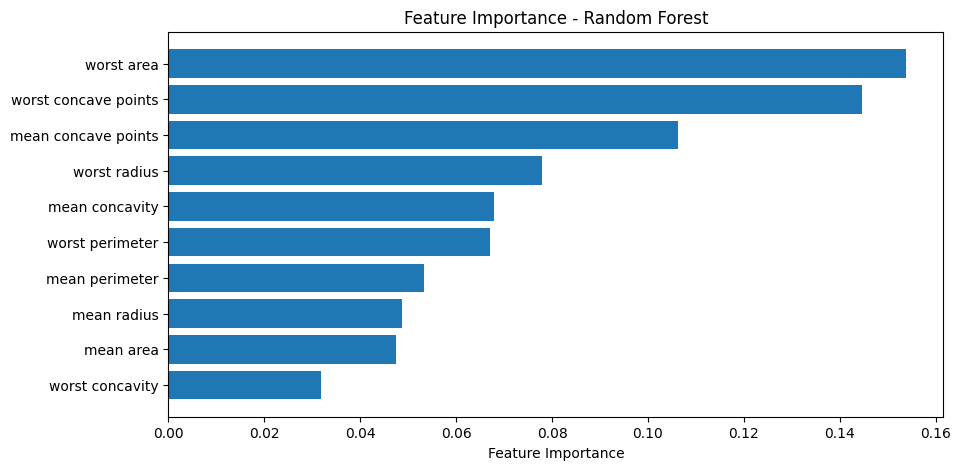


=== PRAKTIKUM 2: PERBANDINGAN EMPAT MODEL (STRATIFIED K-FOLD CV) ===
Decision Tree      : F1-Macro rata-rata = 0.903 (+/- 0.032)
Random Forest      : F1-Macro rata-rata = 0.953 (+/- 0.013)
AdaBoost           : F1-Macro rata-rata = 0.949 (+/- 0.024)
Gradient Boosting  : F1-Macro rata-rata = 0.945 (+/- 0.027)


In [3]:
# ==========================================
# PRAKTIKUM BAB 9: ENSEMBLE LEARNING
# irfan dwi fahrezi
# 202343500217
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("=== PRAKTIKUM 1: PENGARUH N_ESTIMATORS & OOB SCORE (RANDOM FOREST) ===")
# Praktikum 9.6: Eksperimen n_estimators pada Random Forest
for n in [10, 50, 100, 300, 500]:
    model = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=42)
    model.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test))
    print(f"n_estimators={n:3} : OOB={model.oob_score_:.3f}, Test Acc={test_acc:.3f}")

# Visualisasi Feature Importance (Praktikum 9.5)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
importances = rf_model.feature_importances_
idx = np.argsort(importances)[-10:] # Ambil 10 fitur teratas

plt.figure(figsize=(10, 5))
plt.barh([data.feature_names[i] for i in idx], importances[idx])
plt.xlabel("Feature Importance")
plt.title("Feature Importance - Random Forest")
plt.show()


print("\n=== PRAKTIKUM 2: PERBANDINGAN EMPAT MODEL (STRATIFIED K-FOLD CV) ===")
# Praktikum 9.6 (Praktikum 2): Perbandingan 4 Model Ensemble
model_list = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nama, model in model_list.items():
    skor = cross_val_score(model, X, y, cv=skf, scoring="f1_macro")
    print(f"{nama:18} : F1-Macro rata-rata = {skor.mean():.3f} (+/- {skor.std():.3f})")